In [ ]:
exploring which category seperations yield clean quantitative relationships, and

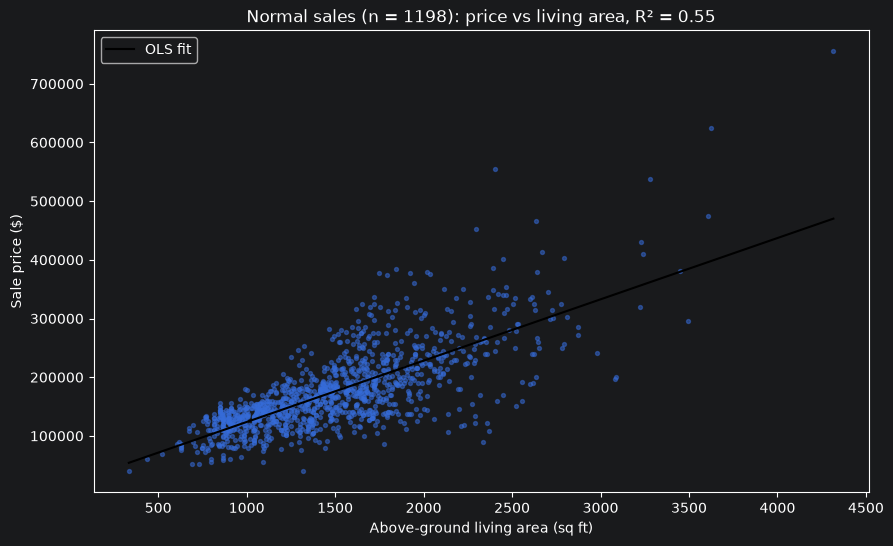

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

train = pd.read_csv("../data/train.csv")
normal = train[train["SaleCondition"] == "Normal"].copy()
x = normal["GrLivArea"].values.astype(float)
y = normal["SalePrice"].values.astype(float)

ols = sm.OLS(y, sm.add_constant(x)).fit()
xs = np.linspace(x.min(), x.max(), 200)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(x, y, s=8, alpha=0.5)
ax.plot(xs, ols.params[0] + ols.params[1] * xs, color="black", lw=1.5, label="OLS fit")
ax.set_xlabel("Above-ground living area (sq ft)"); ax.set_ylabel("Sale price ($)")
ax.set_title(f"Normal sales (n = {len(normal)}): price vs living area, R² = {ols.rsquared:.2f}")
ax.legend(); plt.show()

In [ ]:
this suggests variance / kurt grows wityh house price - we have heteroskedacity clearly from the graph. But for rigours sake, the probability of homoskedacity is

In [7]:
from scipy import stats

X = sm.add_constant(x)
w_lm, w_p, _, _ = het_white(ols.resid, X)

log_p = stats.chi2.logsf(w_lm, df=2)         # log p-value; df = 2 (x and x²)
p_royal_flush = 4 / 2_598_960
flushes = log_p / np.log(p_royal_flush)

print(f"White test: The probability of this distribution of residuals, "
      f"given homoskedasticity, is {np.exp(log_p):.2e}, "
      f"equivalent to being dealt {flushes:.1f} consecutive royal flushes.")

White test: The probability of this distribution of residuals, given homoskedasticity, is 1.83e-60, equivalent to being dealt 10.3 consecutive royal flushes.


,bin,n,median_fitted,resid_sd,sd_lo,sd_hi,cv
0,1,122,107813.0,22032.0,19343.0,24338.0,0.202
1,2,118,121657.0,23116.0,20164.0,25661.0,0.188
2,3,120,135240.0,23466.0,19901.0,26839.0,0.172
3,4,119,149816.0,35422.0,30401.0,40547.0,0.236
4,5,123,164339.0,30631.0,26831.0,34269.0,0.195
5,6,117,176564.0,39738.0,34084.0,44711.0,0.219
6,7,121,190983.0,49336.0,43429.0,54305.0,0.256
7,8,118,203887.0,59656.0,50417.0,67495.0,0.295
8,9,121,224418.0,54667.0,46071.0,61998.0,0.245
9,10,119,270287.0,86191.0,72665.0,99498.0,0.310


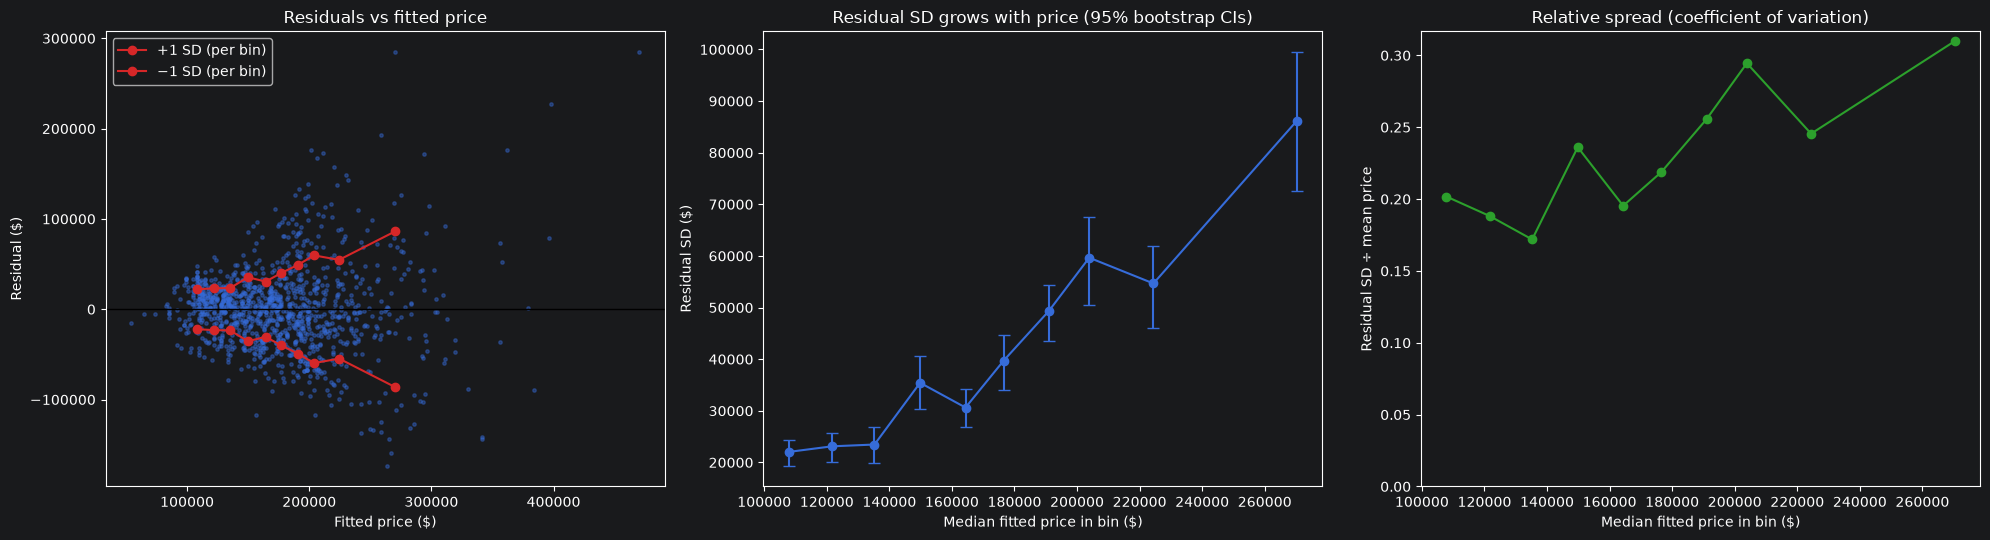

In [8]:
rng = np.random.default_rng(42)
d = pd.DataFrame({"fitted": ols.fittedvalues, "resid": ols.resid, "price": y})
d["bin"] = pd.qcut(d["fitted"], 10, labels=False)

rows = []
for b, g in d.groupby("bin"):
    r = g["resid"].values
    boot = [rng.choice(r, size=len(r), replace=True).std(ddof=1) for _ in range(2000)]
    rows.append({"bin": b + 1, "n": len(g),
                 "median_fitted": g["fitted"].median(),
                 "resid_sd": r.std(ddof=1),
                 "sd_lo": np.percentile(boot, 2.5), "sd_hi": np.percentile(boot, 97.5),
                 "cv": r.std(ddof=1) / g["price"].mean()})
bins = pd.DataFrame(rows)
display(bins.round({"median_fitted": 0, "resid_sd": 0, "sd_lo": 0, "sd_hi": 0, "cv": 3}))

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# (a) Residuals vs fitted values, with ±1 SD per bin
axes[0].scatter(d["fitted"], d["resid"], s=6, alpha=0.4)
axes[0].axhline(0, color="black", lw=1)
axes[0].plot(bins["median_fitted"], bins["resid_sd"], color="tab:red", marker="o", label="+1 SD (per bin)")
axes[0].plot(bins["median_fitted"], -bins["resid_sd"], color="tab:red", marker="o", label="−1 SD (per bin)")
axes[0].set_xlabel("Fitted price ($)"); axes[0].set_ylabel("Residual ($)")
axes[0].set_title("Residuals vs fitted price"); axes[0].legend()

# (b) Residual SD per bin, with bootstrap 95% CIs
axes[1].errorbar(bins["median_fitted"], bins["resid_sd"],
                 yerr=[bins["resid_sd"] - bins["sd_lo"], bins["sd_hi"] - bins["resid_sd"]],
                 fmt="o-", capsize=4)
axes[1].set_xlabel("Median fitted price in bin ($)"); axes[1].set_ylabel("Residual SD ($)")
axes[1].set_title("Residual SD grows with price (95% bootstrap CIs)")

# (c) Coefficient of variation per bin
axes[2].plot(bins["median_fitted"], bins["cv"], "o-", color="tab:green")
axes[2].set_ylim(0, None)
axes[2].set_xlabel("Median fitted price in bin ($)"); axes[2].set_ylabel("Residual SD ÷ mean price")
axes[2].set_title("Relative spread (coefficient of variation)")

plt.tight_layout(); plt.show()

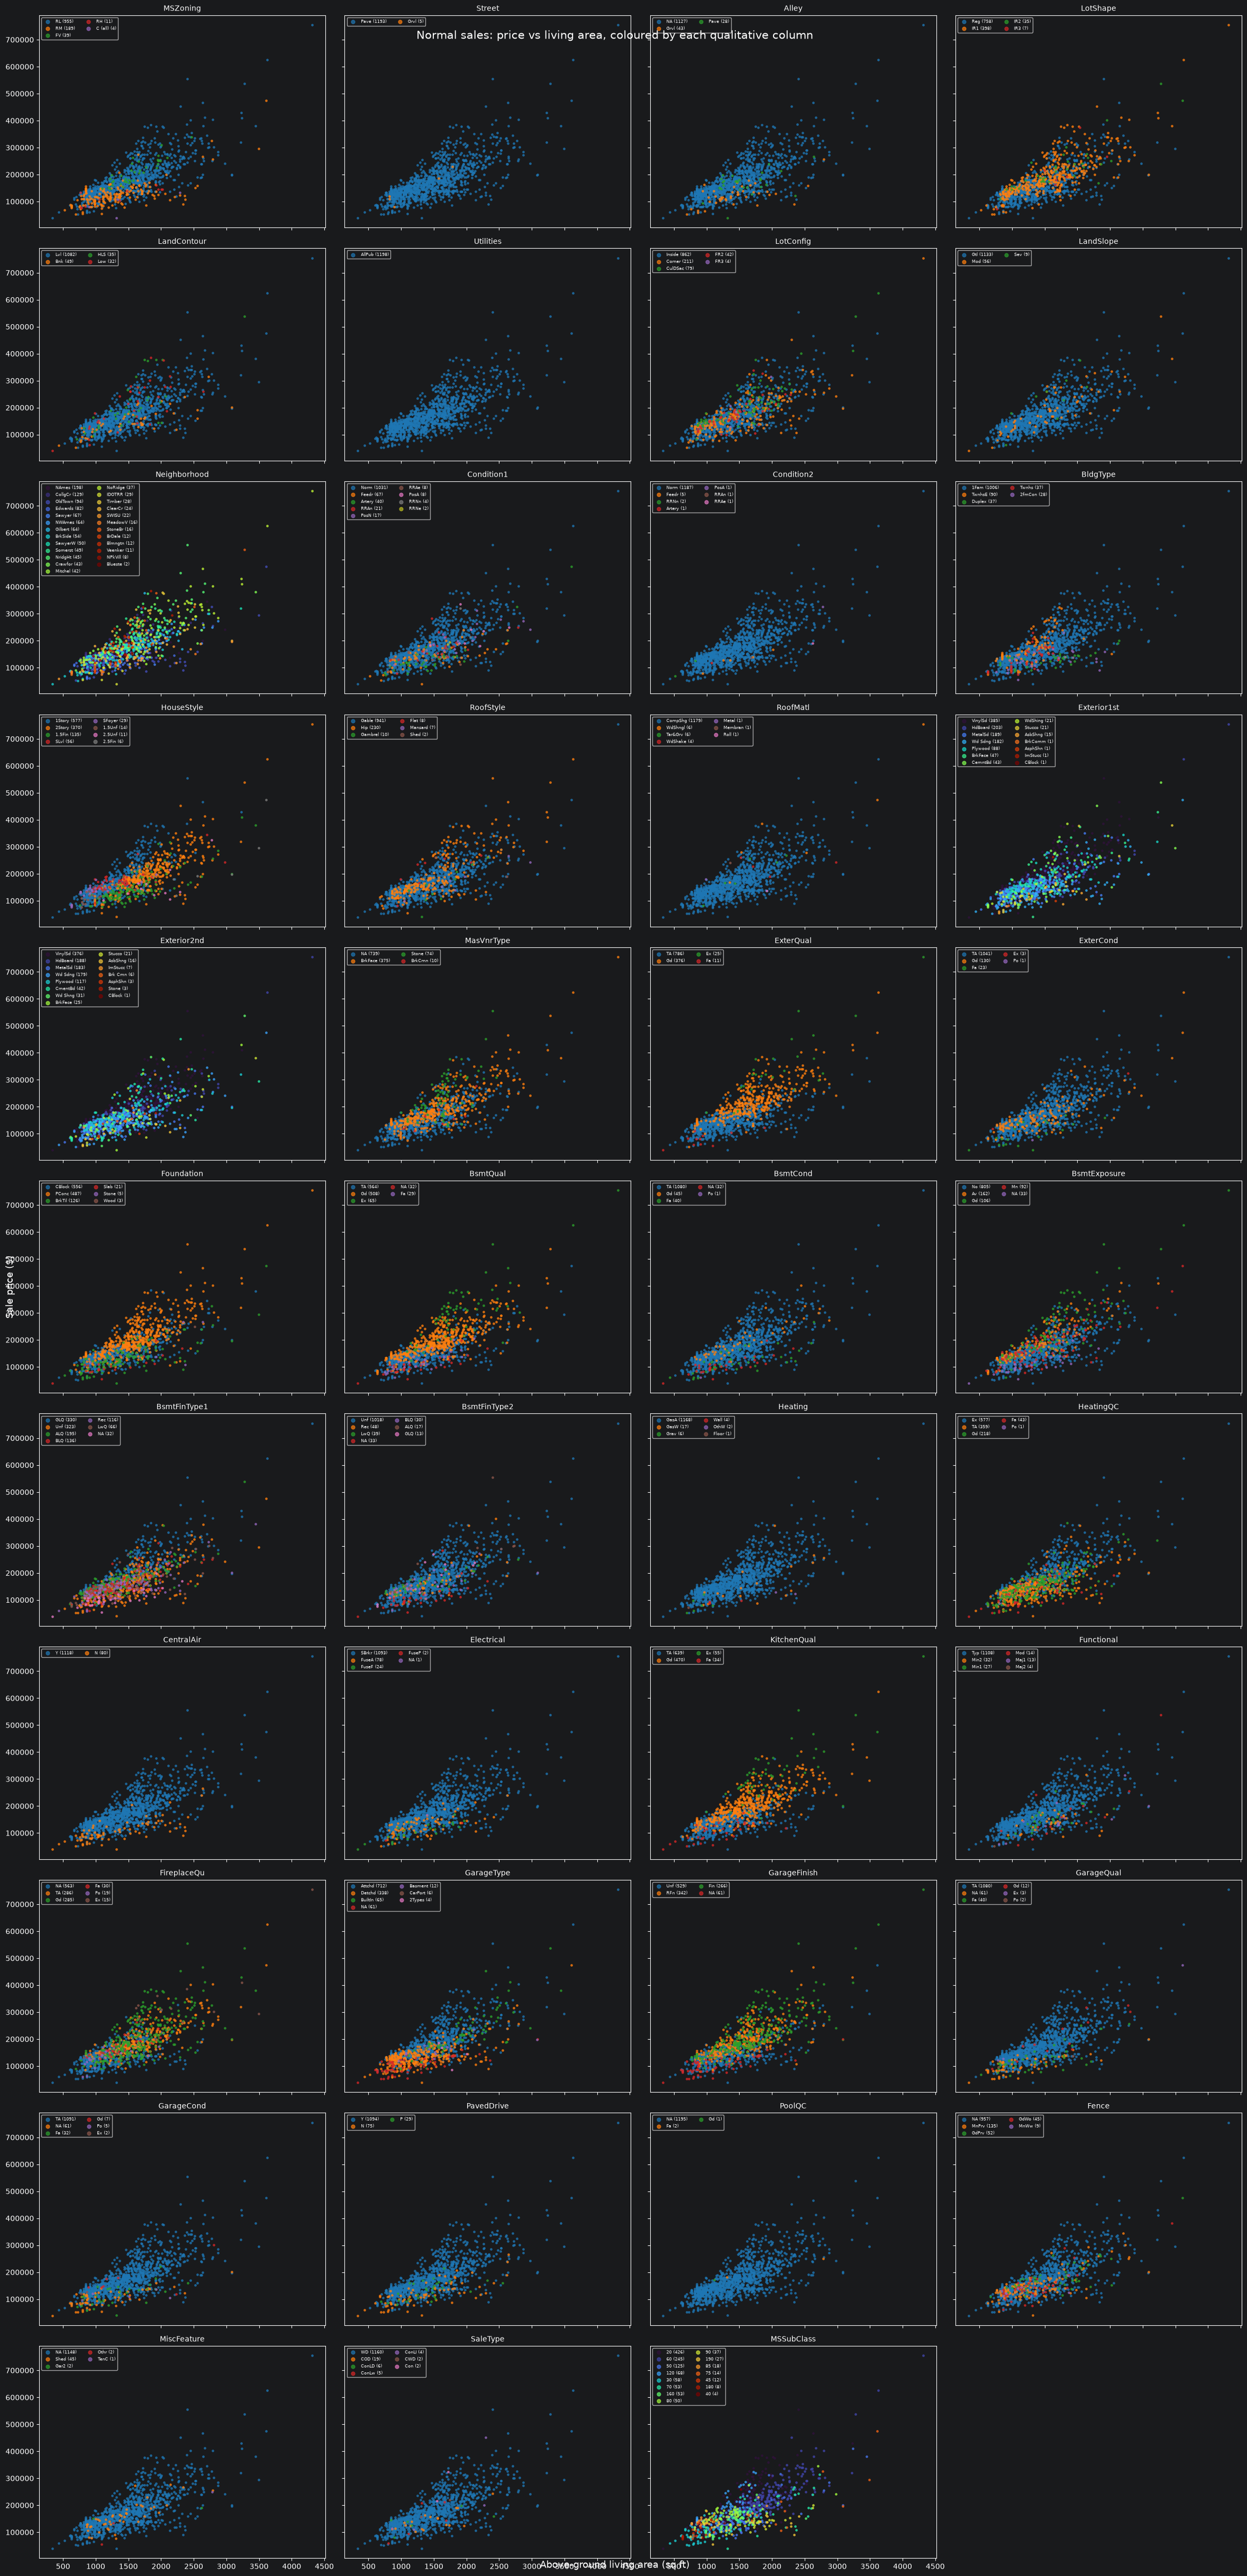

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("../data/train.csv")
normal = train[train["SaleCondition"] == "Normal"].copy()

qual_cols = [c for c in normal.select_dtypes(exclude="number").columns if c != "SaleCondition"]
qual_cols.append("MSSubClass")          # numeric codes, but qualitative
for c in qual_cols:
    normal[c] = normal[c].fillna("NA").astype(str)

ncols = 4
nrows = int(np.ceil(len(qual_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(24, 4.5 * nrows), sharex=True, sharey=True)

for ax, col in zip(axes.flat, qual_cols):
    levels = normal[col].value_counts().index
    cmap = plt.cm.tab10.colors if len(levels) <= 10 else plt.cm.turbo(np.linspace(0, 1, len(levels)))
    for level, colour in zip(levels, cmap):
        g = normal[normal[col] == level]
        ax.scatter(g["GrLivArea"], g["SalePrice"], color=colour, s=6, alpha=0.7,
                   label=f"{level} ({len(g)})")
    ax.set_title(col, fontsize=10)
    ax.legend(fontsize=6, ncol=2, loc="upper left", markerscale=2)

for ax in axes.flat[len(qual_cols):]:
    ax.axis("off")

fig.supxlabel("Above-ground living area (sq ft)", fontsize=13)
fig.supylabel("Sale price ($)", fontsize=13)
fig.suptitle("Normal sales: price vs living area, coloured by each qualitative column", fontsize=15)
plt.tight_layout(); plt.show()

Ranked 150 category levels with n ≥ 30


,column,level,n,median_ratio,share_improved,median_price
1,BsmtExposure,NA,33,0.171,0.88,101800.0
2,BsmtCond,NA,32,0.183,0.88,100900.0
3,BsmtFinType1,NA,32,0.183,0.88,100900.0
4,BsmtQual,NA,32,0.183,0.88,100900.0
5,BsmtFinType2,NA,33,0.211,0.88,101800.0
6,BldgType,Duplex,37,0.228,0.81,135960.0
7,MSSubClass,90,37,0.228,0.81,135960.0
8,CentralAir,N,80,0.267,0.81,100500.0
9,Alley,Grvl,43,0.292,0.79,120000.0
10,BsmtCond,Fa,40,0.341,0.78,117750.0


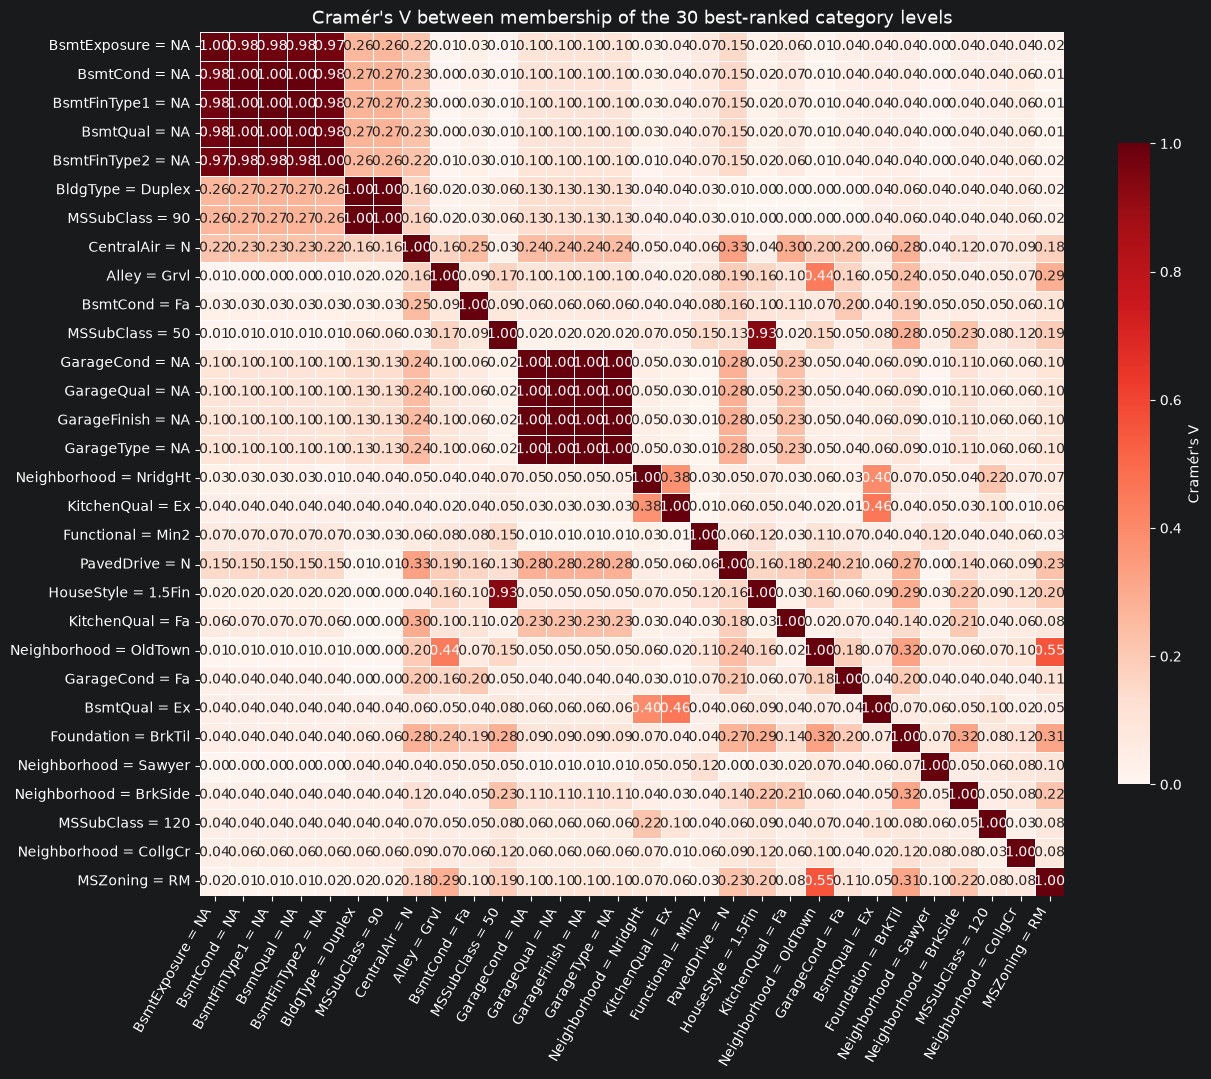

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats.contingency import association

# ---------------- Settings ----------------
MIN_N = 30
N_BEST = 30

train = pd.read_csv("../data/train.csv")
normal = train[train["SaleCondition"] == "Normal"].copy()

qual_cols = [c for c in normal.select_dtypes(exclude="number").columns if c != "SaleCondition"]
qual_cols.append("MSSubClass")
for c in qual_cols:
    normal[c] = normal[c].fillna("NA").astype(str)

# ---------------- Global OLS on all normal sales ----------------
X_all = sm.add_constant(normal["GrLivArea"].astype(float))
global_fit = sm.OLS(normal["SalePrice"].astype(float), X_all).fit()
normal["abs_resid_global"] = global_fit.resid.abs()

# ---------------- Per-level OLS and residual ratios ----------------
rows = []
for col in qual_cols:
    for level, g in normal.groupby(col):
        if len(g) < MIN_N:
            continue
        fit = sm.OLS(g["SalePrice"].astype(float), sm.add_constant(g["GrLivArea"].astype(float))).fit()
        ratio = fit.resid.abs() / g["abs_resid_global"]
        rows.append({"column": col, "level": level, "n": len(g),
                     "median_ratio": ratio.median(),
                     "share_improved": (ratio < 1).mean(),
                     "median_price": g["SalePrice"].median()})

ranking = pd.DataFrame(rows).sort_values("median_ratio").reset_index(drop=True)
ranking.index += 1                                  # rank from 1
print(f"Ranked {len(ranking)} category levels with n ≥ {MIN_N}")
display(ranking.head(N_BEST).round({"median_ratio": 3, "share_improved": 2, "median_price": 0}))

# ---------------- Cramér's V between membership of the top levels ----------------
best = ranking.head(N_BEST)
labels = [f"{c} = {l}" for c, l in zip(best["column"], best["level"])]
indicators = pd.DataFrame({lab: (normal[c] == l).astype(int)
                           for lab, c, l in zip(labels, best["column"], best["level"])})

V = pd.DataFrame(np.eye(N_BEST), index=labels, columns=labels)
for i in range(N_BEST):
    for j in range(i + 1, N_BEST):
        table = pd.crosstab(indicators.iloc[:, i], indicators.iloc[:, j])
        v = association(table.values, method="cramer") if table.shape == (2, 2) else 0.0
        V.iloc[i, j] = V.iloc[j, i] = v

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(V, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, square=True,
            linewidths=0.4, cbar_kws={"label": "Cramér's V", "shrink": 0.7}, ax=ax)
ax.set_title(f"Cramér's V between membership of the {N_BEST} best-ranked category levels", fontsize=13)
plt.xticks(rotation=60, ha="right"); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

In [ ]:
this is heavily biased toward favouring basements as based on above ground area.